# Resume RAG: experiments

This notebook evaluates the resume-matching pipeline (Part A indexing + Part B matching) on the
project's ground truth and compares the design choices behind it: chunking, retrieval mode,
keyword tokenizer, query text, and (in sections 7-12) embedding model, section weights,
calibration, scoring weights and latency.

**Dataset.** 35 synthetic resumes (PDF, DOCX and TXT in eight layouts) and 6 job descriptions.
Every JD x candidate pair has a hand-assigned label: **S** strong (3 per JD), **P** partial (3),
**D** distractor (2, look-alikes that should *not* rank high) or none (27). Labels live in
`data/ground_truth/` and are read only by `rag.evaluation`; the pipeline never sees them.

**Reproduce.** Build the collections once, then run all cells:

```text
python -m scripts.build_experiment_collections
jupyter nbconvert --to notebook --execute --inplace notebooks/experiments.ipynb
```

The notebook holds no logic of its own: every number comes from `rag.evaluation.experiments`
and every table or figure from `rag.evaluation.display`, both covered by tests. Figures are
also saved under `notebooks/figures/`.

In [1]:
import os
import sys
from datetime import date
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # .chroma and data/ are relative to the repo root

from rag.evaluation import display  # noqa: E402

display.notebook_setup()  # quiet libraries, pandas options, one matplotlib style

import matplotlib.pyplot as plt  # noqa: E402

from rag.evaluation.display import (  # noqa: E402
    COLLECTION_COLORS,
    MODE_COLORS,
    bar_chart,
    histogram,
    line_chart,
    melt,
    save_figure,
    to_frame,
)
from rag.evaluation.experiments import (  # noqa: E402
    candidate_chunk_tokens,
    chunk_stats,
    compare_collections,
    compare_retrieval_configs,
    dataset_counts,
    extraction_summary,
    extraction_traps,
    label_counts,
    open_collections,
    query_token_table,
    recall_curve,
    resume_lengths,
    trap_cases,
)
from rag.retrieval import RetrievalConfig  # noqa: E402

AS_OF = date(2026, 11, 1)
C, messages = open_collections()
print("\n".join(messages))
for label, collection in C.items():
    if collection is not None:
        assert collection.sidecar.as_of == AS_OF.isoformat(), (label, collection.sidecar.as_of)
print(f"All open collections were indexed with as_of {AS_OF}.")

section: resumes__section-v1__hf-bge-small-en-v1.5
fixed: resumes__fixed-w120-o30__hf-bge-small-en-v1.5
section-noctx: resumes__section-v1-noctx__hf-bge-small-en-v1.5
section-minilm: resumes__section-v1__hf-all-MiniLM-L6-v2
section-bge-base: resumes__section-v1__hf-bge-base-en-v1.5
All open collections were indexed with as_of 2026-11-01.


## 1. Dataset overview

**Question.** What does the evaluation data look like: formats and layouts, labels per JD,
resume length, and how big are the chunks each chunker produces?

In [2]:
to_frame(dataset_counts()).set_index(["dimension", "value"])

resumes
dimension   value                
format      docx               12
            pdf                14
            txt                 9
layout      academic            2
            classic             7
            compact             4
            minimal             1
            modern              7
            plain               8
            sidebar             4
            table-skills        2
date_format iso                 8
            month_name         13
            numeric             7
            year_only           7

In [3]:
to_frame(label_counts())

,jd_id,S,P,D,none
0,data_engineer,3,3,2,27
1,devops_sre,3,3,2,27
2,frontend,3,3,2,27
3,java_backend,3,3,2,27
4,ml_engineer,3,3,2,27
5,python_backend,3,3,2,27


        count   mean   std    min    25%    50%    75%    max
format                                                       
docx     12.0  217.6  61.6  121.0  189.2  211.5  250.0  324.0
pdf      14.0  221.4  41.8  148.0  195.2  221.0  247.5  297.0
txt       9.0  181.0  52.3   84.0  149.0  200.0  211.0  243.0


notebooks/figures/01_dataset_resume_words.png


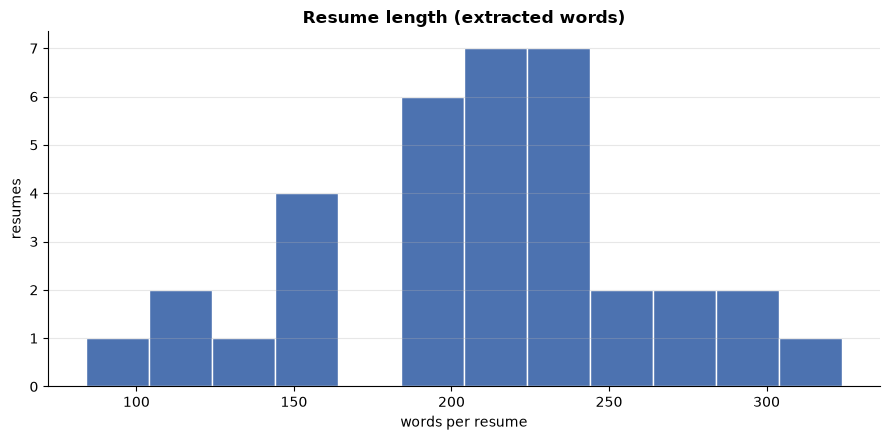

In [4]:
lengths = resume_lengths()
print(to_frame(lengths).groupby("format")["words"].describe().round(1))
fig = histogram(
    [r["words"] for r in lengths],
    bins=12,
    title="Resume length (extracted words)",
    xlabel="words per resume",
)
print(save_figure(fig, "01_dataset", "resume_words"))
plt.show()

notebooks/figures/01_dataset_chunk_words.png


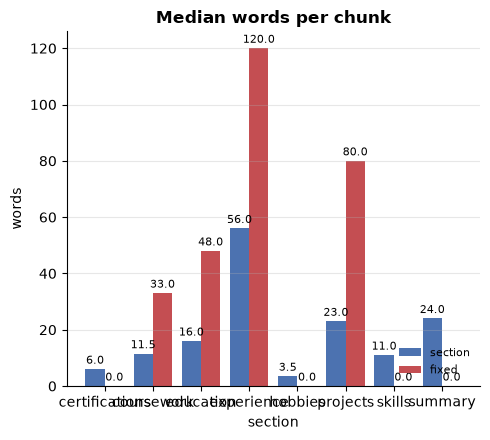

,collection,section,chunks,words_min,words_median,words_mean,words_max
0,section,certifications,9,4,6.0,6.56,10
1,section,coursework,4,8,11.5,11.25,14
2,section,education,35,10,16.0,18.49,43
3,section,experience,79,16,56.0,55.22,97
4,section,hobbies,28,2,3.5,3.79,12
5,section,projects,4,12,23.0,23.50,36
6,section,skills,34,1,11.0,12.03,25
7,section,summary,35,6,24.0,23.37,32
8,fixed,coursework,1,33,33.0,33.00,33
9,fixed,education,7,33,48.0,55.14,120


In [5]:
if C["section"] and C["fixed"]:
    stats = chunk_stats(C["section"]) + chunk_stats(C["fixed"])
    display_frame = to_frame(stats)
    fig = bar_chart(
        stats,
        "section",
        "collection",
        "words_median",
        title="Median words per chunk",
        ylabel="words",
        palette=COLLECTION_COLORS,
        ylim=None,
        digits=1,
    )
    print(save_figure(fig, "01_dataset", "chunk_words"))
    plt.show()
else:
    display_frame = "section or fixed collection missing: skipped"
display_frame

### Findings

- **Formats and layouts.** 35 resumes: 14 PDF, 12 DOCX, 9 TXT, across eight layouts (plain 8,
  classic 7, modern 7, compact 4, sidebar 4, academic 2, table-skills 2, minimal 1) and four
  date formats (month_name 13, iso 8, numeric 7, year_only 7). Some layouts rest on only one or
  two files (minimal 1, academic 2, table-skills 2).
- **Labels.** Every JD has the same shape: 3 S, 3 P, 2 D and 27 none. So strict metrics have
  exactly 3 relevant candidates per JD and lenient metrics 6, which caps P@5 strict at 0.6 and
  lenient R@k at k/6 for k <= 6 (see section 4).
- **Length.** Resumes are short: mean 217.6 extracted words for DOCX (121-324), 221.4 for PDF
  (148-297) and 181.0 for TXT (84-243).
- **Chunks.** The section chunker yields 228 chunks. Experience chunks (79, one per role) have a
  median of 56 words (max 97); summaries 24, education 16, skills 11 and hobbies only 3.5 (28
  chunks). The fixed chunker yields 86 windows, 76 of them labelled experience with a median of
  120 words (the window size), and no summary, skills, hobbies or certifications chunks at all:
  that text is absorbed into windows labelled with another section, so section weights (such as
  the 0.1 on hobbies) cannot act on it.

## 2. Extraction accuracy

**Question.** Does rule-based extraction recover what each resume says (names, skills, years,
education), including the dataset's deliberate edge cases?

In [6]:
to_frame(extraction_summary(C["section"].sidecar))

,metric,value
0,candidates,35.0
1,name exact match,1.0
2,skills precision (micro),1.0
3,skills recall (micro),1.0
4,skills F1 (micro),1.0
5,skills F1 (macro),1.0
6,total years exact match,1.0
7,total years MAE,0.0
8,skill years MAE,0.0
9,skill-year pairs compared,332.0


In [7]:
to_frame(extraction_traps(C["section"]))

,trap,candidate_id,extracted,detail
0,look-alike words are not skills,peter_hughes,Excel,"HVAC engineer: 'Spark Energy Ltd', 'airflow', a Python hobby: no skill"
1,aliases map to canonical skills,noah_williams,"Python 3 -> Python, Postgres -> PostgreSQL, k8s -> Kubernetes, Amazon Web Services -> AWS, JS -> JavaScript, ML -> M...",8 aliases in the skills section
2,"overlapping roles are merged, not summed",mateo_garcia,Python 52 months (4.3 yrs),summed over 2 roles: 76 months (6.3 yrs)
3,listed but never used: 0 months,omar_haddad,"Python 0 months, Django 0 months",evidence: Python in skills; Django in skills
4,internships do not count as experience,ishaan_gupta,total 0 months (0.0 yrs),"Machine Learning Intern (3 months, internship); Data Science Intern (3 months, internship)"
5,skills found in role bullets,nina_kowalski,"AWS, Airflow, Kafka, Python, SQL, Scala, Spark",7 skills; from a skills section: none


### Findings

- **Every extraction metric is perfect.** Name exact match, skills precision, recall and F1
  (micro and macro), total-years exact match, highest-education exact match: all 1.0. Total-years
  MAE and skill-years MAE are 0.0 over 332 skill-year pairs, and 0 of 35 candidates have a
  mismatch.
- **The traps behave as designed.** Peter Hughes (HVAC engineer) yields only Excel: "Spark
  Energy Ltd", "airflow" and a Python hobby produce no skill. Noah Williams' 8 aliases map to
  canonical skills (Python 3 -> Python, Postgres -> PostgreSQL, k8s -> Kubernetes, ...). Mateo
  Garcia's overlapping roles give Python 52 months (4.3 yrs) merged rather than 76 months
  (6.3 yrs) summed. Omar Haddad's Python and Django are listed in his skills section only, so
  they get 0 months. Ishaan Gupta's two 3-month internships give 0 months of experience. Nina
  Kowalski's 7 skills are all found in role bullets, with no skills section.
- **These perfect scores are not evidence of a robust extractor.** The resumes were generated
  from the same contract the extractor implements (section names, date formats, the skill
  vocabulary and its aliases), so 1.0 shows that the rules match the generator, not that they
  generalise. Real resumes, with free-form headings, unusual date ranges, skills outside the
  vocabulary and scanned PDFs, would score lower. Measuring that needs a hand-labelled set of
  real resumes, which this dataset does not include.

## 3. Chunking: section-aware vs fixed-size vs section without contextual header

**Question.** Does section-aware chunking rank better than naive fixed-size windows (all with
bge-small), and does the contextual header line (`Section: Experience | Role: ...`) help?
Retrieval order, before the must-have filter.

In [8]:
CHUNKING = [label for label in ("section", "fixed", "section-noctx") if C[label]]
METRICS = ["P@5_lenient", "R@10_lenient", "MRR_lenient", "nDCG@10", "intrusion@10"]
chunking = compare_collections(
    [C[label] for label in CHUNKING], modes=("semantic", "hybrid"), orders=("retrieval",)
)
to_frame(chunking, ["collection", "mode", *METRICS])

,collection,mode,P@5_lenient,R@10_lenient,MRR_lenient,nDCG@10,intrusion@10
0,section,semantic,0.800,0.778,1.0,0.914,0.050
1,section,hybrid,0.833,0.944,1.0,0.964,0.050
2,fixed,semantic,0.800,0.778,1.0,0.923,0.050
3,fixed,hybrid,0.833,0.944,1.0,0.970,0.083
4,section-noctx,semantic,0.800,0.750,1.0,0.886,0.050
5,section-noctx,hybrid,0.800,0.944,1.0,0.951,0.050


notebooks/figures/03_chunking_metrics.png


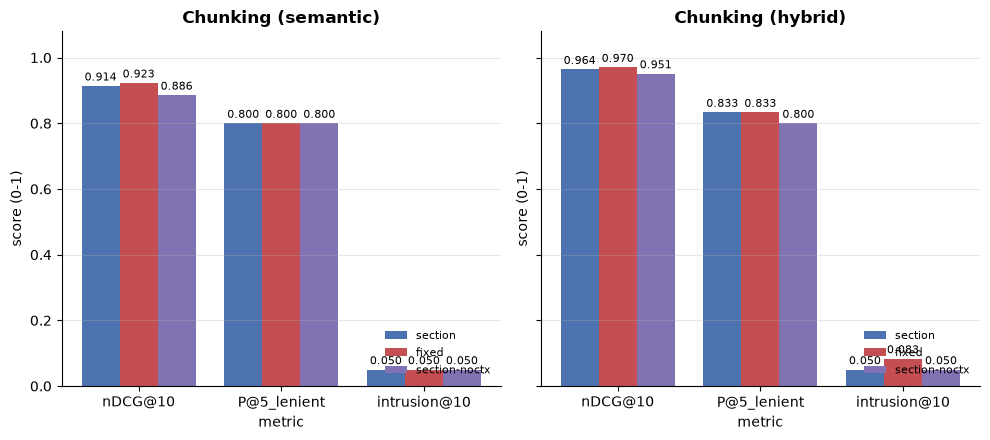

In [9]:
fig = bar_chart(
    melt(chunking, ["collection", "mode"], ["nDCG@10", "P@5_lenient", "intrusion@10"]),
    "metric",
    "collection",
    "value",
    title="Chunking",
    ylabel="score (0-1)",
    palette=COLLECTION_COLORS,
    panel="mode",
)
print(save_figure(fig, "03_chunking", "metrics"))
plt.show()

In [10]:
leak = []
for label in ("fixed", "section"):
    if C[label]:
        leak += candidate_chunk_tokens(C[label], "peter_hughes", contains="Spark Energy")
to_frame(leak, ["collection", "section", "body_start", "matching_lines", "skill_tokens"])

,collection,section,body_start,matching_lines,skill_tokens
0,fixed,experience,0,[Spark Energy Ltd | 2020 – Present],"[skill:spark, skill:excel]"
1,section,experience,2,[Spark Energy Ltd | 2020 – Present],[skill:excel]


### Findings

- **The three chunkings are close on 35 resumes.** In semantic mode, section and fixed have the
  same P@5 lenient (0.800) and R@10 lenient (0.778); fixed is slightly higher on nDCG@10 (0.923
  vs 0.914). In hybrid mode both reach P@5 lenient 0.833 and R@10 lenient 0.944, with nDCG@10
  0.970 for fixed and 0.964 for section. MRR lenient is 1.0 everywhere.
- **Fixed windows let more distractors in.** Hybrid intrusion@10 is 0.083 for fixed against
  0.050 for section, i.e. 5 distractors in the 60 top-10 slots instead of 3.
- **The contextual header helps.** Without the `Section: ... | Role: ...` line, every metric is
  equal or lower: semantic R@10 lenient 0.750 (vs 0.778) and nDCG@10 0.886 (vs 0.914); hybrid
  P@5 lenient 0.800 (vs 0.833) and nDCG@10 0.951 (vs 0.964).
- **Fixed windows leak look-alike skills.** Peter Hughes' line "Spark Energy Ltd | 2020 -
  Present" falls in a fixed window with body_start 0, so the company name is tokenised as
  `skill:spark` (tokens: skill:spark, skill:excel). The section chunk marks its 2 role-header
  lines as header (body_start 2), so only `skill:excel` is indexed.
- **Decision.** The section chunker stays the default. Its slight nDCG gap to fixed is within
  0.006-0.009 on this dataset, while section chunks are what make the metadata,
  section weights, excerpts and header masking possible.

## 4. Retrieval modes: semantic vs keyword vs hybrid

**Question.** On the default collection (section x bge-small), how do semantic-only, BM25-only
and hybrid (RRF) retrieval compare, in retrieval order and after scoring, and where do they
actually differ?

In [11]:
modes = compare_collections([C["section"]])
to_frame(modes, ["mode", "order", "P@5_strict", *METRICS, "R@10_strict", "MRR_strict"])

,mode,order,P@5_strict,P@5_lenient,R@10_lenient,MRR_lenient,nDCG@10,intrusion@10,R@10_strict,MRR_strict
0,semantic,retrieval,0.6,0.800,0.778,1.0,0.914,0.050,1.0,1.0
1,semantic,scored,0.6,0.933,0.944,1.0,0.980,0.050,1.0,1.0
2,keyword,retrieval,0.6,0.967,0.944,1.0,0.969,0.033,1.0,1.0
3,keyword,scored,0.6,0.933,0.944,1.0,0.980,0.033,1.0,1.0
4,hybrid,retrieval,0.6,0.833,0.944,1.0,0.964,0.050,1.0,1.0
5,hybrid,scored,0.6,0.933,0.944,1.0,0.980,0.050,1.0,1.0


notebooks/figures/04_retrieval_modes_recall_curve.png


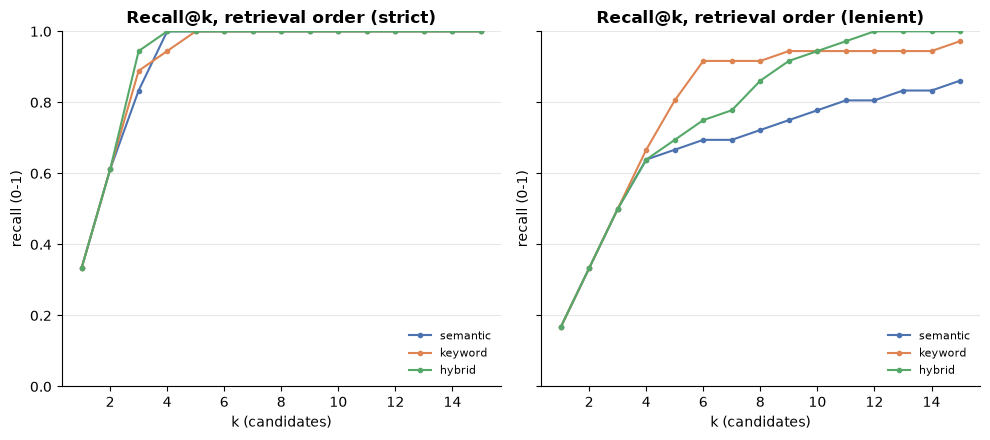

threshold lenient                  strict                 
mode       hybrid keyword semantic hybrid keyword semantic
k                                                         
1           0.167   0.167    0.167  0.333   0.333    0.333
2           0.333   0.333    0.333  0.611   0.611    0.611
3           0.500   0.500    0.500  0.944   0.889    0.833
4           0.639   0.667    0.639  1.000   0.944    1.000
5           0.694   0.806    0.667  1.000   1.000    1.000
6           0.750   0.917    0.694  1.000   1.000    1.000

In [12]:
curves = recall_curve(C["section"], threshold="strict") + recall_curve(
    C["section"], threshold="lenient"
)
fig = line_chart(
    curves,
    "k",
    "recall",
    "mode",
    title="Recall@k, retrieval order",
    xlabel="k (candidates)",
    ylabel="recall (0-1)",
    palette=MODE_COLORS,
    panel="threshold",
)
print(save_figure(fig, "04_retrieval_modes", "recall_curve"))
plt.show()
to_frame([r for r in curves if r["k"] <= 6]).pivot_table(
    index="k", columns=["threshold", "mode"], values="recall"
)

### Findings

- **Several metrics sit at their ceiling and cannot separate the modes.** P@5 strict is 0.6 in
  every row, which is the maximum with 3 S per JD (3 of 5). R@10 strict and MRR (strict and
  lenient) are 1.0 everywhere: every mode puts all three S candidates in the top 10, with one
  of them first. The comparison rests on the lenient metrics, nDCG@10 and intrusion.
- **In retrieval order, keyword (BM25 on skill tokens) is best here.** P@5 lenient 0.967,
  nDCG@10 0.969 and intrusion@10 0.033, against 0.833 / 0.964 / 0.050 for hybrid and 0.800 /
  0.914 / 0.050 for semantic. R@10 lenient is 0.944 for keyword and hybrid and 0.778 for
  semantic. Keyword wins because the JDs' requirements are canonical skills and extraction is
  perfect on this data (section 2).
- **After scoring, the modes converge.** The scored rows are identical on P@5 lenient (0.933),
  R@10 lenient (0.944) and nDCG@10 (0.980); the nDCG beats every retrieval order. Soft mode widens
  the semantic list to every chunk and backfills the other list, so each candidate gets the
  same match score whichever mode retrieved it; the mode only decides which candidates enter the
  scored pool (and the order of tied scores). Semantic and hybrid score all 35 candidates.
  Keyword scores only those with a skill-token match, which is why its scored intrusion@10 is
  0.033 rather than 0.050: a distractor with no matching skill never enters its pool.
- **The recall curves only separate at small k.** Strict recall is identical at k=1 (0.333) and
  k=2 (0.611). It separates at k=3 (hybrid 0.944, keyword 0.889, semantic 0.833) and k=4
  (keyword 0.944, the others 1.000), and is 1.0 for every mode from k=5. Lenient recall is at
  its maximum for every mode up to k=3 (0.167, 0.333, 0.500). It separates from k=4, and at k=6
  keyword reaches 0.917 against 0.750 for hybrid and 0.694 for semantic.
- **What this implies for a large corpus.** With 35 resumes, every candidate gets scored, so
  retrieval quality barely shows after scoring. With thousands of resumes, the pool is a small
  fraction of the corpus and only retrieved candidates are scored. The small-k region of these
  curves is then the one that matters: a candidate missed there is never scored at all.
  Hybrid is kept as the default even though keyword wins here, because keyword alone sees only
  the skill vocabulary, and anything outside it (new tools, synonyms, phrasing) is reachable
  only through the semantic list.

## 5. Keyword tokenizer modes

**Question.** Should BM25 index plain words, only canonical skill tokens (extracted with the
same mention contract as metadata), or both?

In [13]:
TOKENIZERS = {
    mode: RetrievalConfig(keyword_mode=mode) for mode in ("words", "skills", "words+skills")
}
tokenizers = compare_retrieval_configs(
    C["section"], TOKENIZERS, modes=("keyword", "hybrid"), orders=("retrieval",)
)
to_frame(tokenizers, ["variant", "mode", *METRICS])

,variant,mode,P@5_lenient,R@10_lenient,MRR_lenient,nDCG@10,intrusion@10
0,words,keyword,0.867,0.917,1.0,0.933,0.083
1,words,hybrid,0.833,0.944,1.0,0.944,0.067
2,skills,keyword,0.967,0.944,1.0,0.969,0.033
3,skills,hybrid,0.833,0.944,1.0,0.964,0.050
4,words+skills,keyword,0.967,0.944,1.0,0.949,0.083
5,words+skills,hybrid,0.833,0.944,1.0,0.945,0.067


notebooks/figures/05_tokenizer_metrics.png


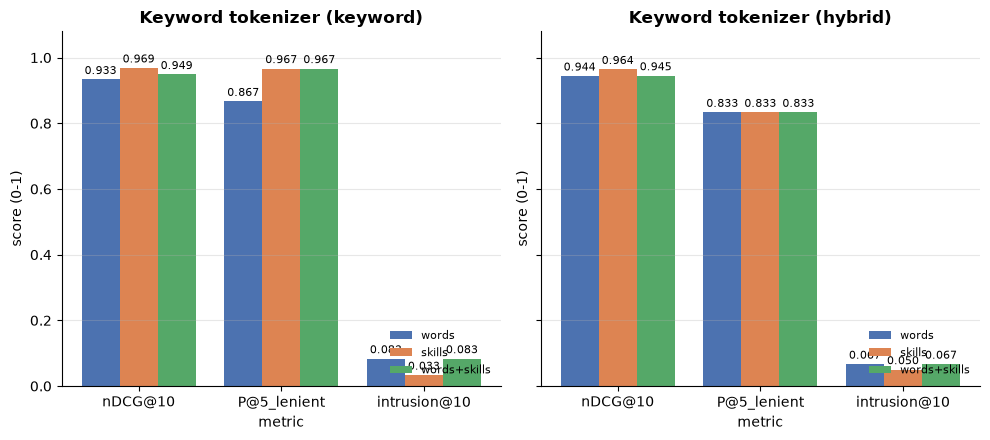

In [14]:
fig = bar_chart(
    melt(tokenizers, ["variant", "mode"], ["nDCG@10", "P@5_lenient", "intrusion@10"]),
    "metric",
    "variant",
    "value",
    title="Keyword tokenizer",
    ylabel="score (0-1)",
    panel="mode",
)
print(save_figure(fig, "05_tokenizer", "metrics"))
plt.show()

In [15]:
traps = trap_cases(C["section"], TOKENIZERS)
to_frame(
    [r for r in traps if r["candidate_id"] in ("peter_hughes", "noah_williams")],
    ["trap", "variant", "rank", "score", "detail"],
)

,trap,variant,rank,score,detail
0,peter_hughes: data_engineer keyword retrieval,words,3,5.280,"experience 5.28, experience 2.14"
1,peter_hughes: 'python' hobbies chunk,words,5,2.050,hobbies weight 0.1: weighted 0.205
2,"noah_williams: aliases (Postgres, k8s, Python 3)",words,3,93.000,"met: Python 6.1 yrs, FastAPI 3.8 yrs, PostgreSQL 6.1 yrs"
3,peter_hughes: data_engineer keyword retrieval,skills,<NA>,NaN,no keyword match
4,peter_hughes: 'python' hobbies chunk,skills,<NA>,NaN,no match (hobbies carry no skill tokens)
5,"noah_williams: aliases (Postgres, k8s, Python 3)",skills,3,93.000,"met: Python 6.1 yrs, FastAPI 3.8 yrs, PostgreSQL 6.1 yrs"
6,peter_hughes: data_engineer keyword retrieval,words+skills,6,5.558,"experience 5.56, experience 2.25"
7,peter_hughes: 'python' hobbies chunk,words+skills,30,2.114,hobbies weight 0.1: weighted 0.211
8,"noah_williams: aliases (Postgres, k8s, Python 3)",words+skills,3,93.000,"met: Python 6.1 yrs, FastAPI 3.8 yrs, PostgreSQL 6.1 yrs"


### Findings

- **Skill tokens are the best BM25 vocabulary.** In keyword mode, `skills` reaches P@5 lenient
  0.967, nDCG@10 0.969 and intrusion@10 0.033. Plain `words` gives 0.867, 0.933 and 0.083.
  `words+skills` matches the P@5 lenient (0.967) but adds plain words back, so nDCG@10 falls to
  0.949 and intrusion rises to 0.083. R@10 lenient is 0.944 for both skill-based variants and
  0.917 for words.
- **In hybrid mode, the tokenizer matters less.** All three variants give P@5 lenient 0.833 and
  R@10 lenient 0.944. `skills` still has the best nDCG@10 (0.964 vs 0.944 for words and 0.945 for
  words+skills) and the lowest intrusion (0.050 vs 0.067).
- **The traps show why.** For data_engineer, Peter Hughes (a distractor) ranks 3rd in keyword
  retrieval with `words` (BM25 5.280, from two experience chunks) and 6th
  with `words+skills` (5.558); with `skills` he does not match at all. His hobbies chunk
  mentioning "python" ranks 5th with `words` (2.050, weighted 0.205 by the 0.1 hobbies weight),
  30th with `words+skills` (2.114), and does not match under `skills`, because hobbies carry no
  skill tokens.
- **Aliases are an extraction concern.** Noah Williams ranks 3rd with a score of 93 under every
  tokenizer ("met: Python 6.1 yrs, FastAPI 3.8 yrs, PostgreSQL 6.1 yrs"), because Postgres, k8s
  and Python 3 are canonicalised at extraction time, before any tokenizer sees them.
- **Decision.** `skills` stays the default keyword mode.

## 6. Query source: `query_text` vs the whole JD

**Question.** Should the semantic query embed only the JD's title, overview,
responsibilities, requirements and nice-to-haves (`query_text`, the default), or the whole
file, company blurb and benefits included?

In [16]:
models = {"bge-small": C["section"].embedder}
if C["section-minilm"]:
    models["MiniLM"] = C["section-minilm"].embedder
to_frame(query_token_table(models))

,jd_id,model,max_tokens,whole,query_text,whole_over,query_over
0,data_engineer,bge-small,512,306,207,False,False
1,data_engineer,MiniLM,256,306,207,True,False
2,devops_sre,bge-small,512,513,338,True,False
3,devops_sre,MiniLM,256,513,338,True,True
4,frontend,bge-small,512,283,192,False,False
5,frontend,MiniLM,256,283,192,True,False
6,java_backend,bge-small,512,324,211,False,False
7,java_backend,MiniLM,256,324,211,True,False
8,ml_engineer,bge-small,512,315,206,False,False
9,ml_engineer,MiniLM,256,315,206,True,False


In [17]:
SOURCES = {"query_text": RetrievalConfig(), "full_text": RetrievalConfig(query_source="full_text")}
sources = compare_retrieval_configs(
    C["section"], SOURCES, modes=("semantic", "hybrid"), orders=("retrieval",)
)
to_frame(sources, ["variant", "mode", *METRICS])

,variant,mode,P@5_lenient,R@10_lenient,MRR_lenient,nDCG@10,intrusion@10
0,query_text,semantic,0.800,0.778,1.000,0.914,0.050
1,query_text,hybrid,0.833,0.944,1.000,0.964,0.050
2,full_text,semantic,0.667,0.806,0.917,0.857,0.017
3,full_text,hybrid,0.800,0.944,1.000,0.957,0.033


In [18]:
per_jd = compare_retrieval_configs(
    C["section"], SOURCES, modes=("semantic", "hybrid"), orders=("retrieval",), per_jd=True
)
to_frame(
    [r for r in per_jd if r["jd_id"] == "devops_sre"],
    ["jd_id", "variant", "mode", "P@5_lenient", "R@10_lenient", "nDCG@10", "intrusion@10"],
)

,jd_id,variant,mode,P@5_lenient,R@10_lenient,nDCG@10,intrusion@10
0,devops_sre,query_text,semantic,0.6,0.833,0.925,0.0
1,devops_sre,query_text,hybrid,0.6,0.833,0.927,0.0
2,devops_sre,full_text,semantic,0.6,0.833,0.865,0.0
3,devops_sre,full_text,hybrid,0.6,0.833,0.900,0.0


### Findings

- **The whole JD does not fit the smaller models.** Token counts (whole file / query_text) are
  306/207 for data_engineer, 513/338 for devops_sre, 283/192 for frontend, 324/211 for
  java_backend, 315/206 for ml_engineer and 394/255 for python_backend. With bge-small's 512-token
  limit, only the whole devops_sre file (513) would be truncated. With MiniLM's 256, every whole
  file is over the limit, and with query_text only devops_sre (338) still is.
- **query_text ranks better in semantic mode.** P@5 lenient 0.800 vs 0.667, MRR lenient 1.000 vs
  0.917 (with the full text, one JD's first hit is not S or P) and nDCG@10 0.914 vs 0.857. The
  full text does better on R@10 lenient (0.806 vs 0.778) and intrusion@10 (0.017 vs 0.050), but
  pays for it at the top of the ranking, where the company blurb and benefits dilute the query.
- **Hybrid mostly hides the difference.** P@5 lenient 0.833 vs 0.800, R@10 lenient 0.944 for
  both, nDCG@10 0.964 vs 0.957 and intrusion 0.050 vs 0.033. The keyword list, which only uses
  the extracted requirements, is unaffected by the query source.
- **devops_sre, the JD over the limit.** nDCG@10 is 0.925 with query_text vs 0.865 with the full
  text in semantic mode, and 0.927 vs 0.900 in hybrid. P@5 lenient (0.6), R@10 lenient (0.833)
  and intrusion@10 (0.0) are the same in all four cases, so the loss is in the order within the
  top 10.
- **Decision.** query_text stays the default: it ranks better, and it keeps every JD under
  bge-small's limit and all but one under MiniLM's.

---

Sections 7-12 (embedding models, section weights, calibration, scoring weights, latency, error
analysis and conclusions) follow in the next step.